## Data Availability

This tutorial uses the **Human Immune** dataset, a multi-batch,
multi-donor scRNA-seq atlas of human PBMCs.

**To use real data**, download the `.h5ad` file from Google Drive
and place it in the `data/` directory:

```bash
# mkdir -p data
# Download from: https://drive.google.com/drive/folders/11PuJRaw_JC7xJhphQklac7eg9AuGHsCE
```

**For quick exploration**, the notebook falls back to a synthetic
mock dataset. Results will differ from real data but the API flow
is identical.


# Tutorial: Cell-type annotation with neighbour-evidence gating

This tutorial walks you through **annotating your own query dataset**
using Cytoneighbor. You will learn:

1. How to train a Cytoneighbor model on a reference
2. How to transfer labels to a query with unknown-gating
3. How to **visualize and interpret** the results
4. How to **export predictions** for your downstream analysis
5. How to **adapt** this workflow to your own data


## 1. Setup and data loading

The cell below loads the dataset if available, or generates a
synthetic mock dataset so you can follow along immediately.


In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import warnings
import cytoneighbor as cn

sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=100, facecolor="white")
print(f"Cytoneighbor version: {cn.__version__}")


D:\Users\86188\miniconda3\envs\smn\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
D:\Users\86188\miniconda3\envs\smn\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
D:\Users\86188\miniconda3\envs\smn\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
D:\Users\86188\miniconda3\envs\smn\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
D:\Users\86188\miniconda3\envs\smn\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_mtx from `anndata` is deprecated. Import annd

Cytoneighbor version: 0.1.0


In [2]:
DATA_PATH = "data/Human immune.h5ad"
USE_MOCK = False

try:
    adata = sc.read_h5ad(DATA_PATH)
    print(f"Loaded real dataset: {adata.n_obs} cells x {adata.n_vars} genes")
except (FileNotFoundError, OSError):
    USE_MOCK = True
    warnings.warn(
        f"Dataset not found at {DATA_PATH!r}. "
        "Generating synthetic mock data for demonstration. "
        "Download the real dataset for production use."
    )
    
    rng = np.random.default_rng(42)
    N_CELLS, N_GENES, N_BATCHES = 200, 600, 5
    
    batches = np.array([f"Batch_{i % (N_BATCHES-1)}" for i in range(N_CELLS)])
    batches[30:40] = "Villani"   # hold-out batch for LOBO
    
    type_list = ["CD4+ T cells", "CD8+ T cells", "NK cells", "NKT cells",
                 "B cells", "Monocytes", "Dendritic cells"]
    cell_types = np.array([type_list[i % 7] for i in range(N_CELLS)])
    
    type_ids = np.array([type_list.index(ct) for ct in cell_types])
    type_means = rng.normal(0, 1, size=(len(type_list), N_GENES))
    batch_list = sorted(set(batches))
    batch_ids = np.array([batch_list.index(b) for b in batches])
    batch_effects = rng.normal(0, 0.2, size=(len(batch_list), N_GENES))
    cell_noise = rng.normal(0, 0.5, size=(N_CELLS, N_GENES))
    X = type_means[type_ids] + batch_effects[batch_ids] + cell_noise
    X -= X.min(axis=0, keepdims=True)
    X += 0.1
    
    gene_names = [f"Gene_{j}" for j in range(N_GENES)]
    adata = sc.AnnData(X.astype(np.float32),
                       obs={"batch": batches, "final_annotation": cell_types},
                       dtype=np.float32)
    adata.var_names = gene_names
    print(f"Generated mock dataset: {adata.n_obs} cells x {adata.n_vars} genes")

print(f"Batches: {adata.obs['batch'].nunique()}")
print(f"Cell types: {adata.obs['final_annotation'].nunique()}")


Generated mock dataset: 200 cells x 600 genes
Batches: 5
Cell types: 7


C:\Users\86188\AppData\Local\Temp\ipykernel_4760\1885862266.py:9: UserWarning: Dataset not found at 'data/Human immune.h5ad'. Generating synthetic mock data for demonstration. Download the real dataset for production use.
  warnings.warn(
D:\Users\86188\miniconda3\envs\smn\lib\site-packages\anndata\_core\anndata.py:381: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(


## 2. Split into reference and query

We simulate a common real-world scenario: you have a well-annotated
reference dataset and an unlabelled query dataset from a different
batch or experiment.


In [4]:
# Hold out one batch as the query
holdout_batch = "Villani"
ref = adata[adata.obs["batch"] != holdout_batch].copy()
query = adata[adata.obs["batch"] == holdout_batch].copy()
print(f"Reference: {ref.n_obs} cells  |  Query: {query.n_obs} cells")

# Check for labels present only in the query (incomplete reference)
ref_labels = set(ref.obs["final_annotation"].unique())
query_labels = set(query.obs["final_annotation"].unique())
missing = query_labels - ref_labels
print(f"Query labels missing from reference: {missing if missing else 'none'}")


Reference: 190 cells  |  Query: 10 cells
Query labels missing from reference: none


## 3. Train Cytoneighbor on the reference

The `load_data` helper prepares the expression matrix and labels.
`fit` trains the SymRelEnc model and stores weights inside
`ref.uns['cytoneighbor']`.


In [5]:
# Prepare data for training
X_ref = ref.X
if hasattr(X_ref, "toarray"):
    X_ref = X_ref.toarray()
labels_ref = ref.obs["final_annotation"].values
cn.load_data(ref, data=X_ref, labels=labels_ref)

# Train the model
cn.fit(ref, epochs=30, early_stopping_patience=5)
print("Training complete. Model stored in ref.uns['cytoneighbor'].")


Data loaded: 190 cells, 600 genes.
Features: 600 genes (v7: no HVG/Scaler)
[Env] Automatically enabling environment key: [batch]
[Split-Group] Group-aware split: train=142 val=48
[Device] using CUDA
[ANN] d_ann=256 (ratio=0.08, min=256, max=1024)
[ValPairs] epoch=1 built=5376 (pos=2688, neg=2688)
==================== Training: SymRelEnc (+ Dynamic Gene-CutMix) ====================
[FAISS] HNSW add (20x256) ...
[done in 0.01s]
[FAISS] HNSW add (20x256) ...
[done in 0.00s]
[FAISS] HNSW add (22x256) ...
[done in 0.00s]
[FAISS] HNSW add (20x256) ...
[done in 0.00s]
[FAISS] HNSW add (20x256) ...
[done in 0.00s]
[FAISS] HNSW add (20x256) ...
[done in 0.00s]
[FAISS] HNSW add (20x256) ...
[done in 0.00s]
[Synth] Synthesis complete: real=142 synth=164 aug=306 (mult_per_dt=1.2, cap_per_dt=600, alpha=1.0, gamma=1.0)
[Proto] built 14 prototypes (per_class=2)
[TrainPairs] epoch=1 built pos=2272 (simple=1136, proto=454, rest=682)
[Probe] epoch=1 anchors=43 cand=4096 topk=32


[Probe]:   0%|          | 0/1 [00:00<?, ?it/s]

[BatchPlan] ep=1 steps=3 | C_each=7 | M_per=133 | B≈931


[SymRel] Epoch 1/1:   0%|          | 0/3 [00:00<?, ?it/s]

[ValPairs] epoch=1 built=5376 (pos=2688, neg=2688)
[Best] AUC -inf -> 1.0000
Model saved to cynb_best.zip
  Train 4.3500 | ValLoss 0.9249 | MonAUC 1.0000 | time 13.86s
  [EarlyStopping] Metric improved to 1.0000. Patience reset to 0.
Loaded best model (AUC=1.0000).
Model saved to cynb_best.zip
Training complete. Model stored in ref.uns['cytoneighbor'].


## 4. Annotate the query cells

`cn.annotate()` transfers labels using ranked neighbour evidence.
With `enable_unknown=True`, cells with weak evidence are retained
as *Unknown* rather than forced into the closest label.


In [8]:
# Transfer labels with unknown-gating
cn.annotate(
    ref,
    "final_annotation",
    query,
    enable_unknown=True,
    score_mode="logit",
)

# Quick look at predictions
print(query.obs['cytoneighbor_prediction'].value_counts())
print(f"\nUnknown rate: {(query.obs['cytoneighbor_prediction'] == 'Unknown').mean():.1%}")


[Annotate] reference cells=190, classes=7, query cells=10
[FAISS] HNSW add (190x256) ...
[done in 0.00s]


[Annotate]:   0%|          | 0/1 [00:00<?, ?it/s]

[Annotate] Written to obs['cytoneighbor_prediction'], obs['cytoneighbor_prediction_pretty'], obs['cytoneighbor_confidence'], obsm['cytoneighbor_probs']; C=7; Unknown=0; efSearch=760
cytoneighbor_prediction
B cells            2
NK cells           2
NKT cells          2
CD4+ T cells       1
CD8+ T cells       1
Dendritic cells    1
Monocytes          1
Unknown            0
Name: count, dtype: int64

Unknown rate: 0.0%


## 5. Visualize the annotations

A picture is worth a thousand statistics. Let's see where the
predictions agree with the ground truth, and where Cytoneighbor
chose to say *Unknown*.


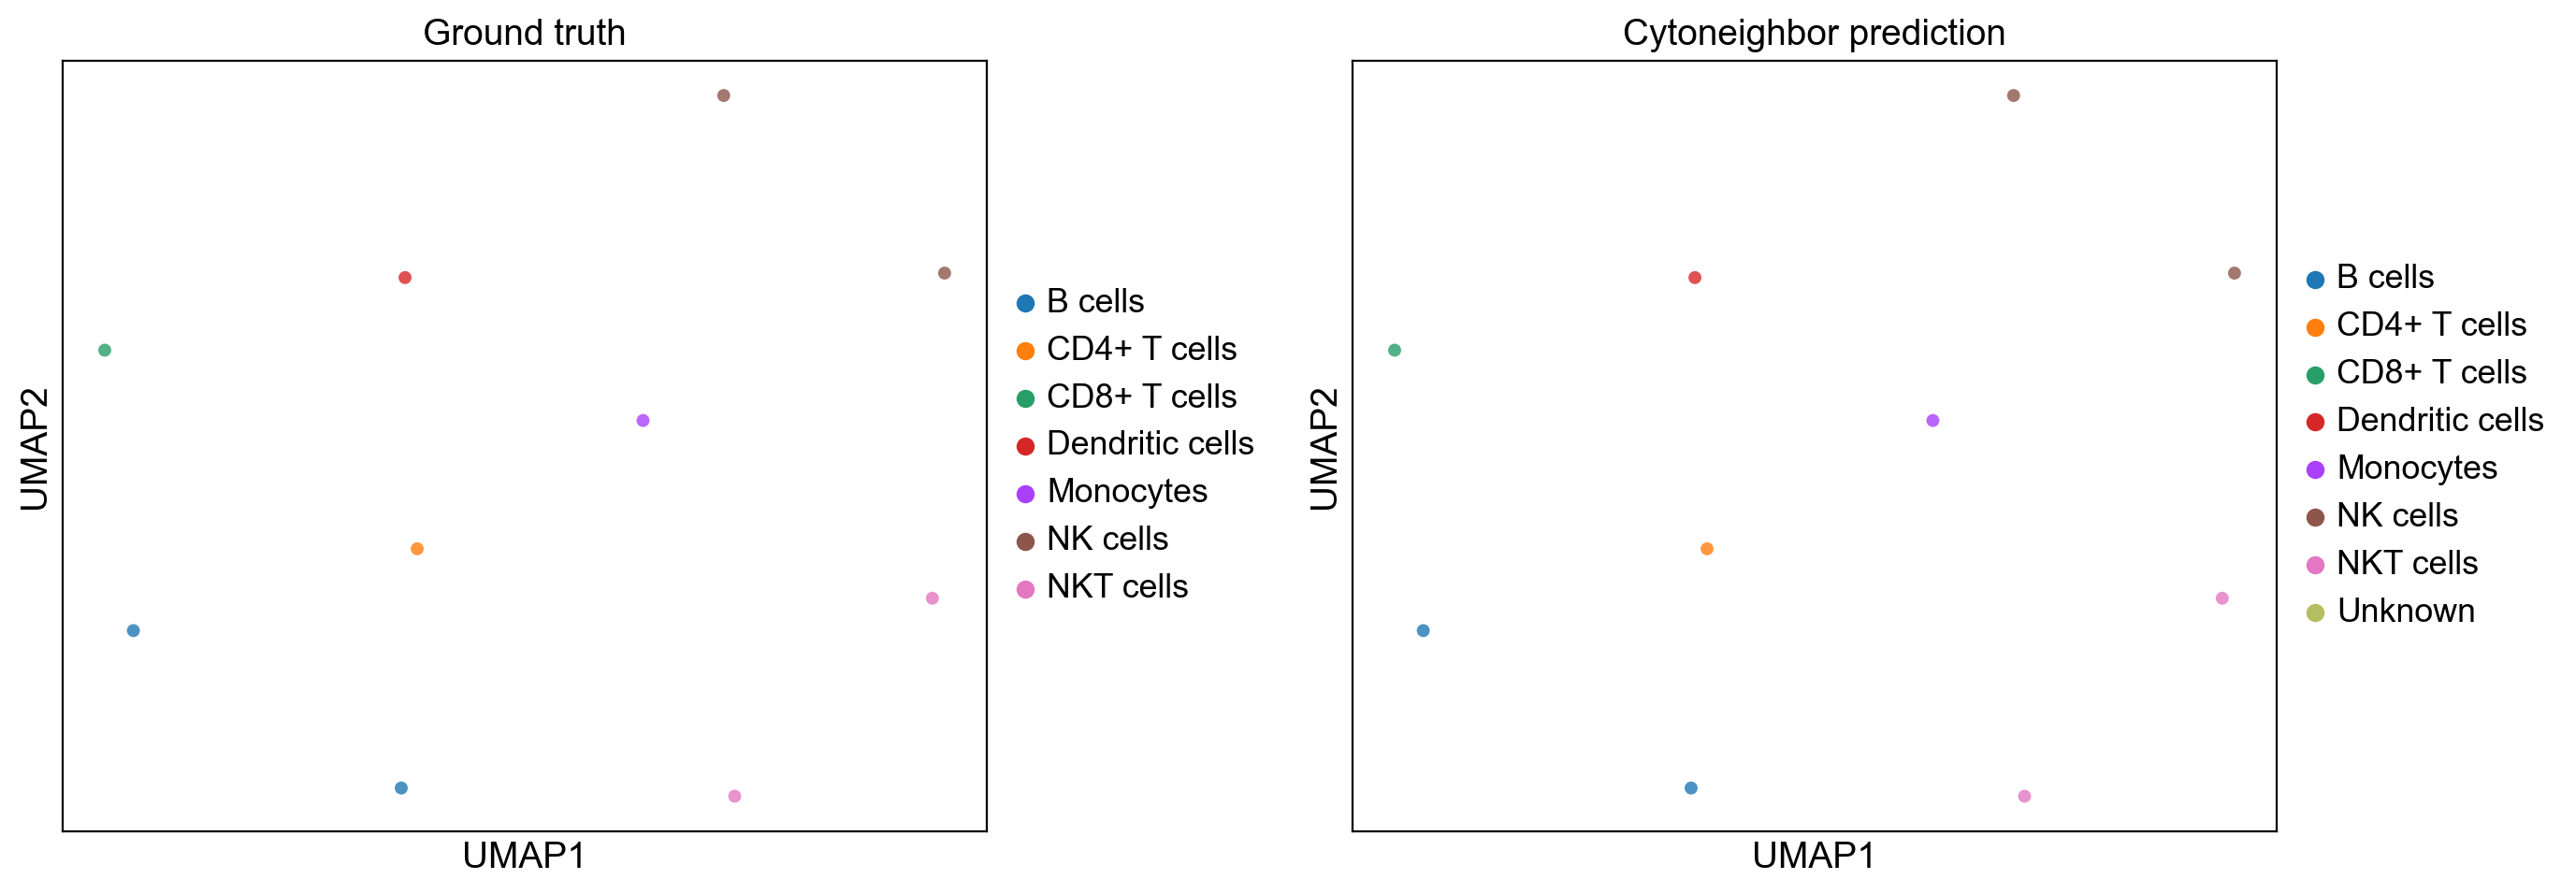

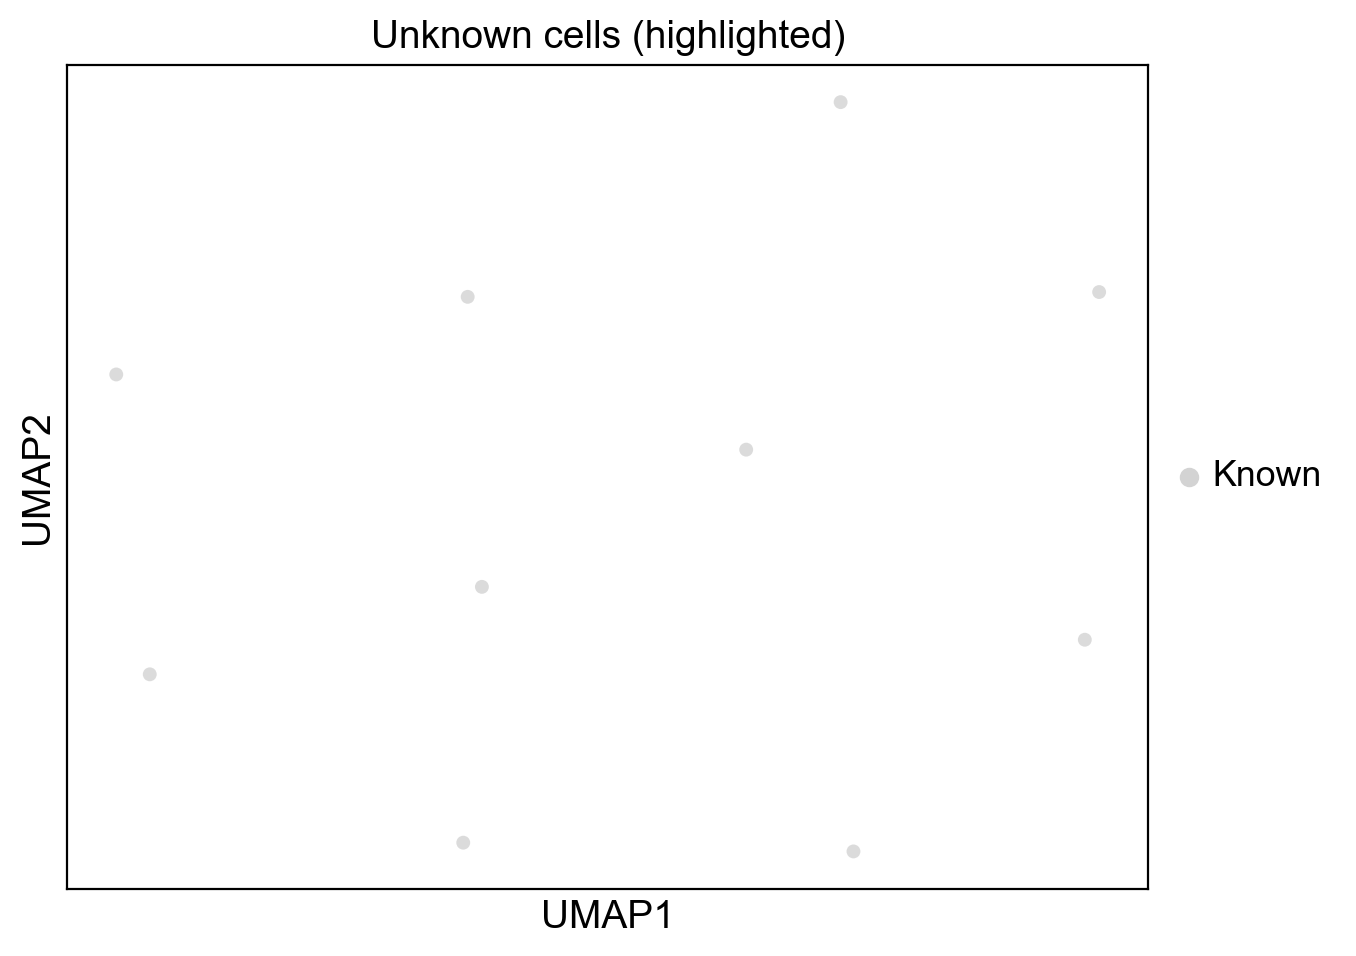

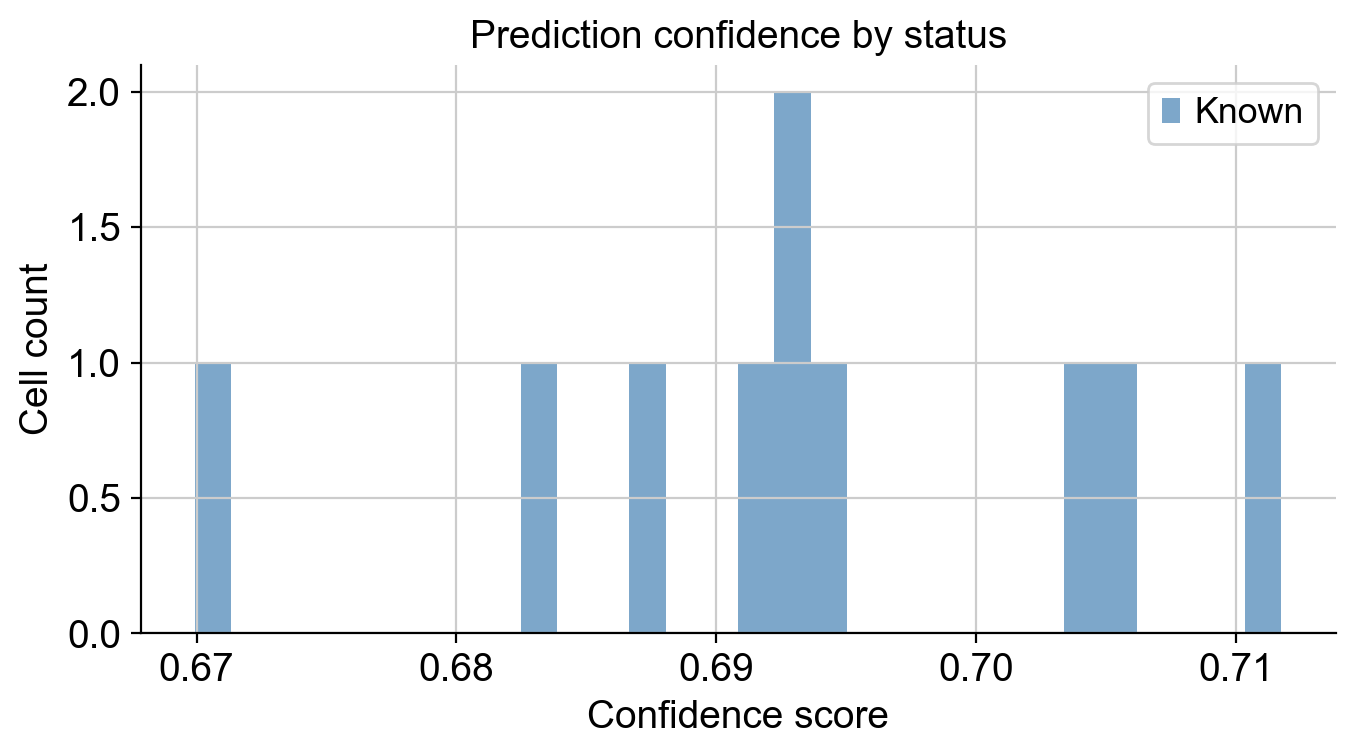

In [11]:
import matplotlib.pyplot as plt

# --- Fix PCA for small query sets ---
sc.pp.normalize_total(query, target_sum=1e4)
sc.pp.log1p(query)

n_comps = min(30, query.n_obs - 1, query.n_vars - 1)
n_comps = max(1, n_comps)
sc.pp.pca(query, n_comps=n_comps)

n_neighbors = min(15, query.n_obs - 1)
n_neighbors = max(2, n_neighbors)
sc.pp.neighbors(query, n_neighbors=n_neighbors)
sc.tl.umap(query, init_pos='random')

# --- Panel 1: Ground truth vs Prediction ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sc.pl.umap(
    query, color="final_annotation", ax=axes[0], show=False,
    title="Ground truth", legend_loc="right margin", frameon=True,
    size=100, alpha=0.8,
)

sc.pl.umap(
    query, color="cytoneighbor_prediction", ax=axes[1], show=False,
    title="Cytoneighbor prediction", legend_loc="right margin", frameon=True,
    size=100, alpha=0.8,
)

plt.tight_layout()
plt.show()

# --- Panel 2: Highlight Unknown cells ---
query.obs["is_unknown"] = pd.Categorical(
    query.obs["cytoneighbor_prediction"] == "Unknown"
).rename_categories({True: "Unknown", False: "Known"})

fig, ax = plt.subplots(figsize=(7, 5))

sc.pl.umap(
    query, color="is_unknown", ax=ax, show=False,
    title="Unknown cells (highlighted)",
    palette={"Unknown": "red", "Known": "lightgrey"},
    size=100, alpha=0.8,
)

plt.tight_layout()
plt.show()

# --- Panel 3: Confidence score distribution ---
if "cytoneighbor_confidence" in query.obs.columns:
    fig, ax = plt.subplots(figsize=(7, 4))
    
    known = query.obs[query.obs["cytoneighbor_prediction"] != "Unknown"]
    unknown = query.obs[query.obs["cytoneighbor_prediction"] == "Unknown"]
    
    ax.hist(known["cytoneighbor_confidence"], bins=30, alpha=0.7, label="Known", color="steelblue")
    if len(unknown) > 0:
        ax.hist(unknown["cytoneighbor_confidence"], bins=30, alpha=0.7, label="Unknown", color="coral")
    
    ax.set_xlabel("Confidence score")
    ax.set_ylabel("Cell count")
    ax.legend()
    ax.set_title("Prediction confidence by status")
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    plt.tight_layout()
    plt.show()

## 6. Export results for your pipeline

Once satisfied with the annotations, export them for downstream
analysis (differential expression, trajectory inference, etc.).


In [12]:
# Option 1: Save the full AnnData with predictions embedded
query.write("annotated_query.h5ad")
print("Saved: annotated_query.h5ad")

# Option 2: Export predictions as a CSV
export_cols = ["cytoneighbor_prediction", "cytoneighbor_confidence"]
available = [c for c in export_cols if c in query.obs.columns]
query.obs[available].to_csv("cytoneighbor_predictions.csv")
print("Saved: cytoneighbor_predictions.csv")

# Option 3: Use predictions as input to other tools
# e.g., run differential expression per predicted cell type
# sc.tl.rank_genes_groups(query, groupby="cytoneighbor_prediction")


Saved: annotated_query.h5ad
Saved: cytoneighbor_predictions.csv


## 7. Adapt to your own data

To use this workflow on your own data, you only need to change
three things:

```python
import cytoneighbor as cn
import scanpy as sc

# 1. Load YOUR data
ref  = sc.read_h5ad("your_reference.h5ad")
query = sc.read_h5ad("your_query.h5ad")

# 2. Specify YOUR label column
cn.fit(ref, label_key="your_cell_type_column")

# 3. Annotate
cn.annotate(ref, "your_cell_type_column", query, enable_unknown=True)
```

That's it. The rest of the workflow (visualization, export) stays
the same regardless of your dataset.


## Summary

You have learned how to:

- Train a Cytoneighbor model on a reference dataset
- Annotate a query dataset with **unknown-gating** enabled
- **Visualize** predictions on UMAP and inspect confidence scores
- **Export** results for your downstream analysis
- **Adapt** the workflow to your own data

Next steps:
- Try the [Integration tutorial](tutorial_integration.ipynb)
  to learn how Cytoneighbor handles multi-batch data
- Run `python main.py run-all` to reproduce the paper figures
